<a href="https://colab.research.google.com/github/Gabriel408-bit/ASSIGNMENT-/blob/main/EDA_DecisionTree_CaseStudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define raw dataset provided in the case study
raw_data = {
    'Student_ID': [1001, 1002, 1003, 1004, 1005, 1001, 1006, 1007, 1008, 1009],
    'County': ['Nakuru', 'Narok', 'Nakuru', 'Narok', 'Kakamega',
               'Nakuru', 'Nairobi', None, 'Narok', 'Nakuru'],
    'Study_Hours_Per_Week': [15, 8, 20, None, 12, 15, 30, 10, 25, 18],
    'Attendance Percent': [85, 60, 92, 55, 78, 85, 95, 65, 88, None],
    'Fee_Balance_Ksh': [0, 15000, 0, 25000, 5000, 0, 0, 18000, 2000, 12000],
    'Previous_Grade': [72, 48, 85, 45, 65, 72, 90, 50, 82, 58],
    'Student_Type': ['Regular', 'Regular', 'Scholarship', 'Regular',
                     'Scholarship', 'Regular', 'Regular', 'Scholarship',
                     'Regular', 'Regular'],
    'Academic_Risk': [0, 1, 0, 1, 0, 0, 0, 1, 0, 1]
}

# Create DataFrame and standardize column name (remove space)
df = pd.DataFrame(raw_data)
df.rename(columns={'Attendance Percent': 'Attendance_Percent'}, inplace=True)

# Inspection Outputs
print("--- 1. DataFrame Shape ---")
print(df.shape)

print("\n--- 2. Data Types ---")
print(df.dtypes)

print("\n--- 3. Summary Statistics ---")
print(df.describe())

--- 1. DataFrame Shape ---
(10, 8)

--- 2. Data Types ---
Student_ID                int64
County                   object
Study_Hours_Per_Week    float64
Attendance_Percent      float64
Fee_Balance_Ksh           int64
Previous_Grade            int64
Student_Type             object
Academic_Risk             int64
dtype: object

--- 3. Summary Statistics ---
        Student_ID  Study_Hours_Per_Week  Attendance_Percent  Fee_Balance_Ksh  \
count    10.000000              9.000000            9.000000        10.000000   
mean   1004.600000             17.000000           78.111111      7700.000000   
std       2.875181              7.123903           14.598326      9153.627089   
min    1001.000000              8.000000           55.000000         0.000000   
25%    1002.250000             12.000000           65.000000         0.000000   
50%    1004.500000             15.000000           85.000000      3500.000000   
75%    1006.750000             20.000000           88.000000     14250.000

In [2]:
# Check for duplicates
print("Duplicate rows count:", df.duplicated().sum())

# Drop duplicate records (keeping the first occurrence)
df = df.drop_duplicates().reset_index(drop=True)

# Check missing values per column
print("\nMissing values before cleaning:\n", df.isnull().sum())

# Handle Missing Values:
# 1. Fill missing County with the mode (most frequent county)
df['County'] = df['County'].fillna(df['County'].mode()[0])

# 2. Fill missing Study_Hours_Per_Week with the median
df['Study_Hours_Per_Week'] = df['Study_Hours_Per_Week'].fillna(df['Study_Hours_Per_Week'].median())

# 3. Fill missing Attendance_Percent with the median
df['Attendance_Percent'] = df['Attendance_Percent'].fillna(df['Attendance_Percent'].median())

print("\nMissing values after cleaning:\n", df.isnull().sum())
print("\nCleaned DataFrame Shape:", df.shape)

Duplicate rows count: 1

Missing values before cleaning:
 Student_ID              0
County                  1
Study_Hours_Per_Week    1
Attendance_Percent      1
Fee_Balance_Ksh         0
Previous_Grade          0
Student_Type            0
Academic_Risk           0
dtype: int64

Missing values after cleaning:
 Student_ID              0
County                  0
Study_Hours_Per_Week    0
Attendance_Percent      0
Fee_Balance_Ksh         0
Previous_Grade          0
Student_Type            0
Academic_Risk           0
dtype: int64

Cleaned DataFrame Shape: (9, 8)


/tmp/ipykernel_2555/70584174.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Academic_Risk', y='Attendance_Percent', data=df, palette='Set2')


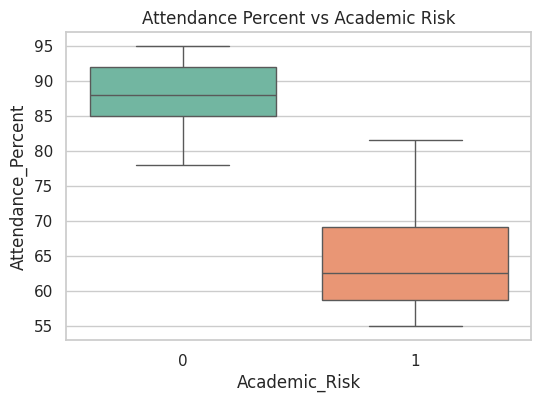

/tmp/ipykernel_2555/70584174.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Academic_Risk', y='Study_Hours_Per_Week', data=df, palette='Set2')


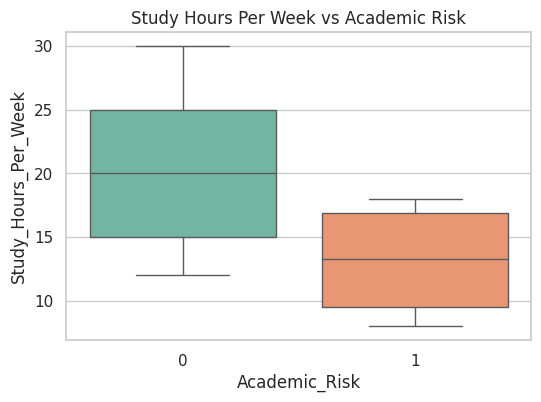

/tmp/ipykernel_2555/70584174.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Academic_Risk', y='Fee_Balance_Ksh', data=df, palette='Set2')


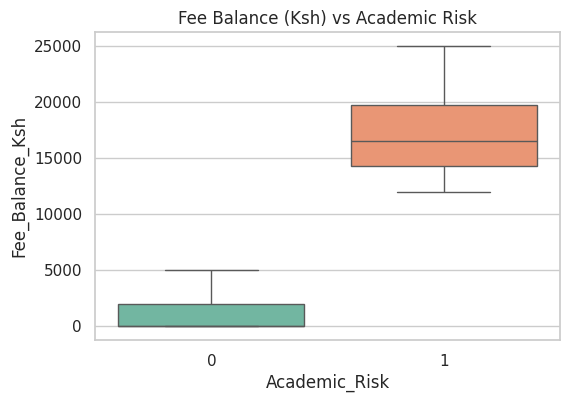

In [3]:
# Set visualization style
sns.set_theme(style="whitegrid")

# Plot 1: Attendance vs Academic Risk
plt.figure(figsize=(6, 4))
sns.boxplot(x='Academic_Risk', y='Attendance_Percent', data=df, palette='Set2')
plt.title('Attendance Percent vs Academic Risk')
plt.show()

# Plot 2: Study Hours vs Academic Risk
plt.figure(figsize=(6, 4))
sns.boxplot(x='Academic_Risk', y='Study_Hours_Per_Week', data=df, palette='Set2')
plt.title('Study Hours Per Week vs Academic Risk')
plt.show()

# Plot 3: Fee Balance vs Academic Risk
plt.figure(figsize=(6, 4))
sns.boxplot(x='Academic_Risk', y='Fee_Balance_Ksh', data=df, palette='Set2')
plt.title('Fee Balance (Ksh) vs Academic Risk')
plt.show()

In [4]:
# Feature 1: Attendance Category (Low < 70%, Moderate 70-85%, High > 85%)
def categorize_attendance(att):
    if att < 70:
        return 'Low'
    elif att <= 85:
        return 'Moderate'
    else:
        return 'High'

df['Attendance_Category'] = df['Attendance_Percent'].apply(categorize_attendance)

# Feature 2: Fee Balance Indicator (1 if fee balance > 0, else 0)
df['Has_Fee_Balance'] = (df['Fee_Balance_Ksh'] > 0).astype(int)

print(df[['Student_ID', 'Attendance_Percent', 'Attendance_Category', 'Fee_Balance_Ksh', 'Has_Fee_Balance']].head())

   Student_ID  Attendance_Percent Attendance_Category  Fee_Balance_Ksh  \
0        1001                85.0            Moderate                0   
1        1002                60.0                 Low            15000   
2        1003                92.0                High                0   
3        1004                55.0                 Low            25000   
4        1005                78.0            Moderate             5000   

   Has_Fee_Balance  
0                0  
1                1  
2                0  
3                1  
4                1  


In [5]:
from sklearn.preprocessing import StandardScaler

# Drop Student_ID as it's a unique identifier, not a feature
X_raw = df.drop(columns=['Student_ID', 'Academic_Risk'])

# One-Hot Encoding for categorical variables
categorical_cols = ['County', 'Student_Type', 'Attendance_Category']
X_encoded = pd.get_dummies(X_raw, columns=categorical_cols, drop_first=True)

# Standardize numerical variables
numerical_cols = ['Study_Hours_Per_Week', 'Attendance_Percent', 'Fee_Balance_Ksh', 'Previous_Grade']
scaler = StandardScaler()
X_encoded[numerical_cols] = scaler.fit_transform(X_encoded[numerical_cols])

print("Processed Features Head:\n", X_encoded.head())

Processed Features Head:
    Study_Hours_Per_Week  Attendance_Percent  Fee_Balance_Ksh  Previous_Grade  \
0             -0.324191            0.534663        -0.978374        0.367189   
1             -1.371575           -1.301965         0.736957       -1.129279   
2              0.423941            1.048918        -0.978374        1.177776   
3             -0.099751           -1.669290         1.880512       -1.316338   
4             -0.773070            0.020407        -0.406597       -0.069281   

   Has_Fee_Balance  County_Nairobi  County_Nakuru  County_Narok  \
0                0           False           True         False   
1                1           False          False          True   
2                0           False           True         False   
3                1           False          False          True   
4                1           False          False         False   

   Student_Type_Scholarship  Attendance_Category_Low  \
0                     False       

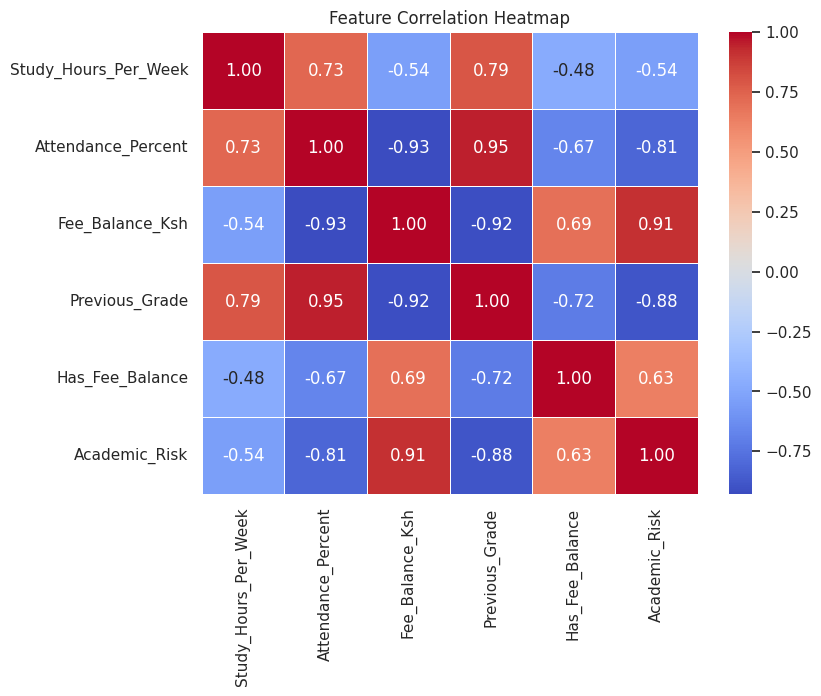

In [6]:
# Combine processed numerical/binary features with target for correlation
corr_df = X_encoded.copy()
corr_df['Academic_Risk'] = df['Academic_Risk']

# Compute correlation matrix
corr_matrix = corr_df[numerical_cols + ['Has_Fee_Balance', 'Academic_Risk']].corr()

# Plot Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

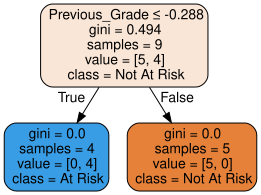

In [7]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz
import graphviz

# Define features (X) and target (y)
X = X_encoded
y = df['Academic_Risk']

# Train Decision Tree Classifier with max_depth=3
dt_classifier = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_classifier.fit(X, y)

# Export and visualize using Graphviz
dot_data = export_graphviz(
    dt_classifier,
    out_file=None,
    feature_names=X.columns,
    class_names=['Not At Risk', 'At Risk'],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = graphviz.Source(dot_data)
graph.render("student_academic_risk_tree", format="png", cleanup=True)
display(graph)